In [2]:
%pip install torch torchvision lime scikit-image matplotlib scikit-learn

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.3/127.3 MB 10.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 8.7 MB/s eta 0:00:00
  DEPRECATION: Building 'lime' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'lime'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=66aa197d79221e1637b19a09c08046b3f1890708c8282722ba5dbebc227b2dba
  Stored in directory: /Users/abdulhaseebmalik/Library/Caches/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec0644

In [3]:
import torch
from torchvision import datasets, transforms

print(torch.__version__)

tf = transforms.ToTensor()
train = datasets.MNIST("data", train=True, download=True, transform=tf)
test = datasets.MNIST("data", train=False, download=True, transform=tf)

print(len(train), len(test))

2.14.1


100%|███████████████████████████████████████| 9.91M/9.91M [00:27<00:00, 358kB/s]
100%|██████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 93.5kB/s]
100%|██████████████████████████████████████| 1.65M/1.65M [00:01<00:00, 1.10MB/s]
100%|██████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 3.71MB/s]

60000 10000


In [4]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Using:", device)

Using: mps


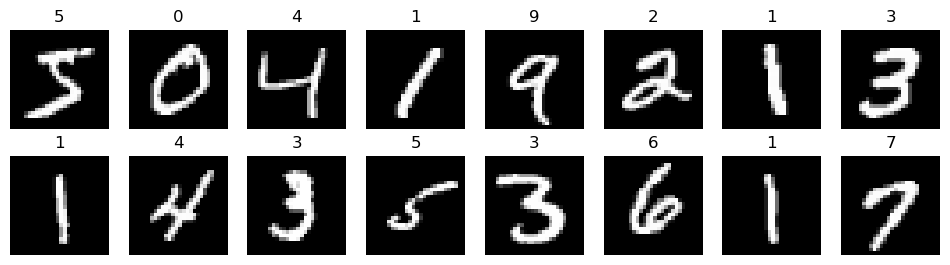

Class counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [5]:
tf = transforms.ToTensor()
train = datasets.MNIST("data", train=True, download=True, transform=tf)
test = datasets.MNIST("data", train=False, download=True, transform=tf)

train_loader = DataLoader(train, batch_size=128, shuffle=True)
test_loader = DataLoader(test, batch_size=256)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, (img, label) in zip(axes.flat, train):
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(label); ax.axis("off")
plt.show()

print("Class counts:", np.bincount(train.targets.numpy()))

In [6]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, dropout=0.25):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(dropout)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 28x28 -> 14x14
        x = self.pool(F.relu(self.conv2(x)))   # 14x14 -> 7x7
        x = self.drop(x.flatten(1))
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

In [7]:
def train_model(model, epochs=5, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train(); total = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
            total += loss.item() * len(x)
        print(f"Epoch {ep+1}: train loss {total/len(train):.4f}, test acc {evaluate(model)[0]:.4f}")
    return model

def evaluate(model):
    model.eval(); preds, labels = [], []
    with torch.no_grad():
        for x, y in test_loader:
            preds.append(model(x.to(device)).argmax(1).cpu()); labels.append(y)
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return (preds == labels).mean(), preds, labels

Epoch 1: train loss 0.4100, test acc 0.9343
Epoch 2: train loss 0.1933, test acc 0.9531
Epoch 3: train loss 0.1403, test acc 0.9598
Epoch 4: train loss 0.1092, test acc 0.9677
Epoch 5: train loss 0.0881, test acc 0.9708
Epoch 1: train loss 0.2811, test acc 0.9813
Epoch 2: train loss 0.0814, test acc 0.9868
Epoch 3: train loss 0.0597, test acc 0.9886
Epoch 4: train loss 0.0486, test acc 0.9905
Epoch 5: train loss 0.0432, test acc 0.9909
              precision    recall  f1-score   support

           0     0.9908    0.9939    0.9924       980
           1     0.9930    1.0000    0.9965      1135
           2     0.9941    0.9864    0.9903      1032
           3     0.9960    0.9911    0.9935      1010
           4     0.9869    0.9980    0.9924       982
           5     0.9845    0.9955    0.9900       892
           6     0.9968    0.9864    0.9916       958
           7     0.9798    0.9932    0.9865      1028
           8     0.9907    0.9867    0.9887       974
           9     0.

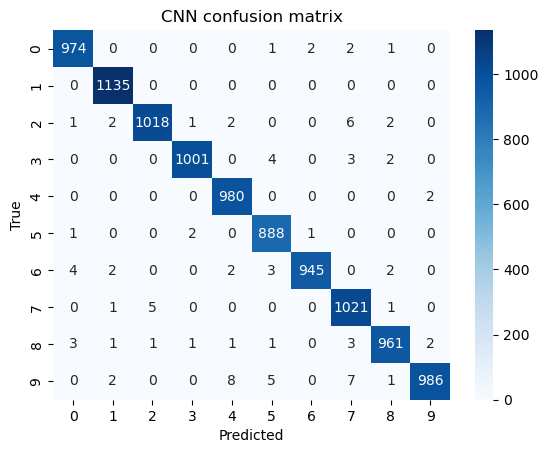

In [8]:
mlp = train_model(MLP(), epochs=5)
cnn = train_model(CNN(), epochs=5)

acc, preds, labels = evaluate(cnn)
print(classification_report(labels, preds, digits=4))

sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("CNN confusion matrix"); plt.show()

In [9]:
torch.save(cnn.state_dict(), "cnn_baseline.pt")

Total errors: 91


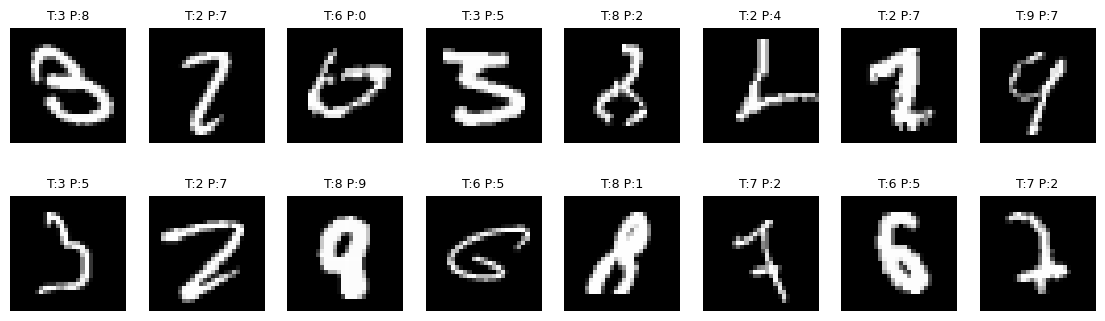

In [10]:
_, preds, labels = evaluate(cnn)
wrong = np.where(preds != labels)[0]
print("Total errors:", len(wrong))

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.flat, wrong[:16]):
    ax.imshow(test[i][0].squeeze(), cmap="gray")
    ax.set_title(f"T:{labels[i]} P:{preds[i]}", fontsize=9)
    ax.axis("off")
plt.show()

In [11]:
results = []
for lr in [1e-2, 1e-3, 1e-4]:
    for drop in [0.0, 0.25, 0.5]:
        print(f"--- lr={lr}, dropout={drop}")
        m = train_model(CNN(dropout=drop), epochs=5, lr=lr)
        results.append((lr, drop, evaluate(m)[0]))

import pandas as pd
df = pd.DataFrame(results, columns=["lr", "dropout", "test_acc"])
print(df.sort_values("test_acc", ascending=False))

--- lr=0.01, dropout=0.0
Epoch 1: train loss 0.2311, test acc 0.9770
Epoch 2: train loss 0.0785, test acc 0.9630
Epoch 3: train loss 0.0645, test acc 0.9784
Epoch 4: train loss 0.0580, test acc 0.9752
Epoch 5: train loss 0.0546, test acc 0.9833
--- lr=0.01, dropout=0.25
Epoch 1: train loss 0.3022, test acc 0.9781
Epoch 2: train loss 0.1501, test acc 0.9809
Epoch 3: train loss 0.1316, test acc 0.9821
Epoch 4: train loss 0.1284, test acc 0.9821
Epoch 5: train loss 0.1163, test acc 0.9862
--- lr=0.01, dropout=0.5
Epoch 1: train loss 0.3648, test acc 0.9785
Epoch 2: train loss 0.2102, test acc 0.9833
Epoch 3: train loss 0.1919, test acc 0.9844
Epoch 4: train loss 0.1846, test acc 0.9845
Epoch 5: train loss 0.1794, test acc 0.9850
--- lr=0.001, dropout=0.0
Epoch 1: train loss 0.2210, test acc 0.9830
Epoch 2: train loss 0.0572, test acc 0.9858
Epoch 3: train loss 0.0391, test acc 0.9881
Epoch 4: train loss 0.0294, test acc 0.9886
Epoch 5: train loss 0.0237, test acc 0.9890
--- lr=0.001, drop

In [15]:
from torch.utils.data import random_split

train_sub, val_sub = random_split(train, [54000, 6000], generator=torch.Generator().manual_seed(42))
sub_loader = DataLoader(train_sub, batch_size=128, shuffle=True)
val_loader = DataLoader(val_sub, batch_size=256)

def acc_on(model, loader):
    model.eval(); correct = 0
    with torch.no_grad():
        for x, y in loader:
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return correct / len(loader.dataset)

def fit(model, epochs=5, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        for x, y in sub_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); F.cross_entropy(model(x), y).backward(); opt.step()
    return model

val_results = []
for lr in [1e-3, 1e-2]:          # skip 1e-4, it clearly underfits
    for drop in [0.0, 0.25, 0.5]:
        m = fit(CNN(dropout=drop), epochs=5, lr=lr)
        val_results.append((lr, drop, acc_on(m, val_loader)))
        print(lr, drop, round(val_results[-1][2], 4))

best = max(val_results, key=lambda r: r[2])
print("Best on validation:", best)

final = fit(CNN(dropout=best[1]), epochs=5, lr=best[0])
print("Final test accuracy (reported once):", round(acc_on(final, test_loader), 4))
torch.save(final.state_dict(), "cnn_final.pt")

0.001 0.0 0.9878
0.001 0.25 0.9887
0.001 0.5 0.988
0.01 0.0 0.9822
0.01 0.25 0.9843
0.01 0.5 0.9823
Best on validation: (0.001, 0.25, 0.9886666666666667)
Final test accuracy (reported once): 0.9888


In [16]:
final = CNN(dropout=0.25).to(device)
final.load_state_dict(torch.load("cnn_final.pt"))

<All keys matched successfully>

In [17]:
aug_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.ToTensor()
])
train_aug_full = datasets.MNIST("data", train=True, download=True, transform=aug_tf)
train_aug = torch.utils.data.Subset(train_aug_full, train_sub.indices)   # same 54k images as before
aug_loader = DataLoader(train_aug, batch_size=128, shuffle=True)

def fit_aug(model, epochs=5, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        for x, y in aug_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); F.cross_entropy(model(x), y).backward(); opt.step()
    return model

aug_model = fit_aug(CNN(dropout=0.25), epochs=5, lr=1e-3)
print("Augmented  val acc:", round(acc_on(aug_model, val_loader), 4))
print("Augmented test acc:", round(acc_on(aug_model, test_loader), 4))
print("Baseline   test acc:", round(acc_on(final, test_loader), 4))

Augmented  val acc: 0.9852
Augmented test acc: 0.9882
Baseline   test acc: 0.9888


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

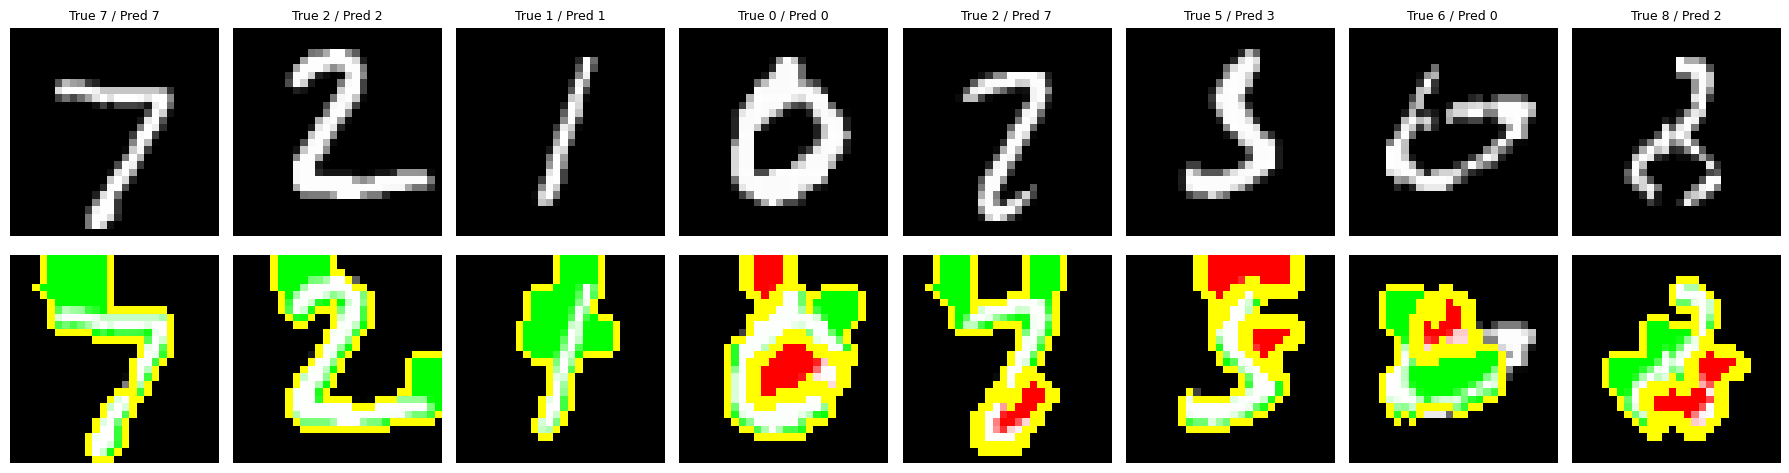

In [18]:
from lime import lime_image
from skimage.segmentation import mark_boundaries, slic

final.eval()

def predict_fn(imgs):                      # imgs: (N, 28, 28, 3) from LIME
    x = torch.tensor(imgs[..., 0], dtype=torch.float32).unsqueeze(1).to(device)
    with torch.no_grad():
        return F.softmax(final(x), dim=1).cpu().numpy()

seg = lambda im: slic(im, n_segments=40, compactness=1, start_label=0)
explainer = lime_image.LimeImageExplainer()

def explain(idx):
    img = test[idx][0].squeeze().numpy()
    rgb = np.stack([img] * 3, axis=-1).astype(np.double)
    exp = explainer.explain_instance(rgb, predict_fn, top_labels=1, hide_color=0,
                                     num_samples=1000, segmentation_fn=seg)
    label = exp.top_labels[0]
    tmp, mask = exp.get_image_and_mask(label, positive_only=False, num_features=5, hide_rest=False)
    return img, mark_boundaries(tmp, mask), label

_, preds, labels = evaluate(final)
right = np.where(preds == labels)[0][:4]
wrong = np.where(preds != labels)[0][:4]

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for col, i in enumerate(list(right) + list(wrong)):
    img, overlay, lab = explain(i)
    axes[0, col].imshow(img, cmap="gray"); axes[0, col].axis("off")
    axes[0, col].set_title(f"True {labels[i]} / Pred {preds[i]}", fontsize=9)
    axes[1, col].imshow(overlay); axes[1, col].axis("off")
plt.tight_layout(); plt.savefig("lime_examples.png", dpi=150); plt.show()

eps=0.00  baseline=0.9888  augmented=0.9882
eps=0.05  baseline=0.9623  augmented=0.9566
eps=0.10  baseline=0.8889  augmented=0.8710
eps=0.15  baseline=0.7325  augmented=0.6846
eps=0.20  baseline=0.4803  augmented=0.3689
eps=0.25  baseline=0.2442  augmented=0.1490
eps=0.30  baseline=0.1174  augmented=0.0694


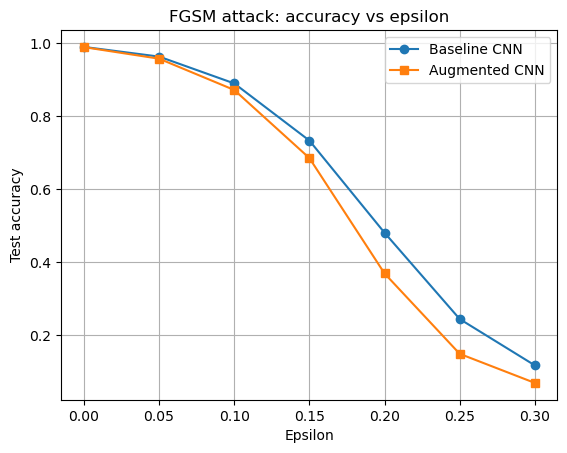

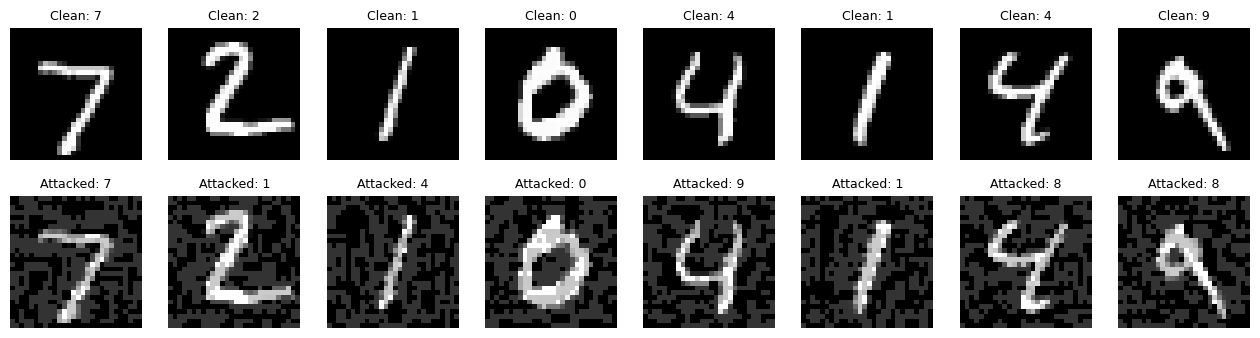

In [19]:
def fgsm(model, x, y, eps):
    x = x.clone().detach().to(device); y = y.to(device)
    x.requires_grad = True
    loss = F.cross_entropy(model(x), y)
    model.zero_grad(); loss.backward()
    x_adv = x + eps * x.grad.sign()
    return torch.clamp(x_adv, 0, 1).detach()

def acc_under_attack(model, eps):
    model.eval(); correct = 0
    for x, y in test_loader:
        x_adv = fgsm(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x_adv).argmax(1).cpu() == y).sum().item()
    return correct / len(test)

epsilons = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
acc_final = [acc_under_attack(final, e) for e in epsilons]
acc_aug   = [acc_under_attack(aug_model, e) for e in epsilons]

for e, a, b in zip(epsilons, acc_final, acc_aug):
    print(f"eps={e:.2f}  baseline={a:.4f}  augmented={b:.4f}")

plt.plot(epsilons, acc_final, "o-", label="Baseline CNN")
plt.plot(epsilons, acc_aug, "s-", label="Augmented CNN")
plt.xlabel("Epsilon"); plt.ylabel("Test accuracy"); plt.legend(); plt.grid(True)
plt.title("FGSM attack: accuracy vs epsilon")
plt.savefig("fgsm_curve.png", dpi=150); plt.show()

# Examples of images that fool the model
x, y = next(iter(test_loader))
x_adv = fgsm(final, x[:8], y[:8], 0.2)
with torch.no_grad():
    p_clean = final(x[:8].to(device)).argmax(1).cpu()
    p_adv = final(x_adv).argmax(1).cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(x[i].squeeze(), cmap="gray"); axes[0, i].set_title(f"Clean: {p_clean[i].item()}", fontsize=9); axes[0, i].axis("off")
    axes[1, i].imshow(x_adv[i].cpu().squeeze(), cmap="gray"); axes[1, i].set_title(f"Attacked: {p_adv[i].item()}", fontsize=9); axes[1, i].axis("off")
plt.savefig("fgsm_examples.png", dpi=150); plt.show()

eps=0.00  baseline=0.9888  augmented=0.9882  adv-trained=0.9900
eps=0.05  baseline=0.9623  augmented=0.9566  adv-trained=0.9818
eps=0.10  baseline=0.8889  augmented=0.8710  adv-trained=0.9745
eps=0.15  baseline=0.7325  augmented=0.6846  adv-trained=0.9689
eps=0.20  baseline=0.4803  augmented=0.3689  adv-trained=0.9513
eps=0.25  baseline=0.2442  augmented=0.1490  adv-trained=0.9153
eps=0.30  baseline=0.1174  augmented=0.0694  adv-trained=0.8416


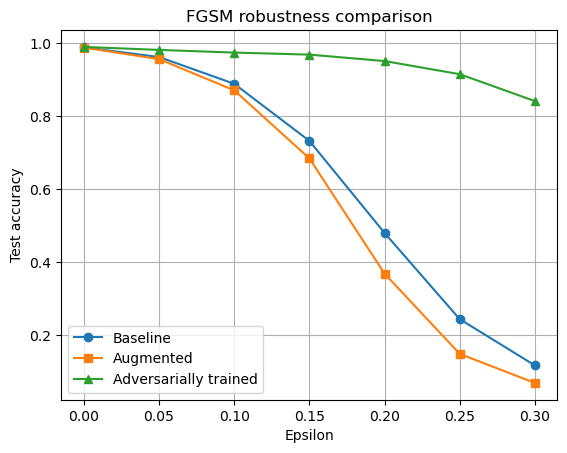

In [23]:
def fit_adv(model, epochs=5, lr=1e-3, eps=0.15):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        for x, y in sub_loader:
            x, y = x.to(device), y.to(device)
            model.eval()                       # craft the attack without dropout noise
            x_adv = fgsm(model, x, y, eps)
            model.train()
            xb = torch.cat([x, x_adv]); yb = torch.cat([y, y])   # train on clean + attacked
            opt.zero_grad(); F.cross_entropy(model(xb), yb).backward(); opt.step()
    return model

adv_model = fit_adv(CNN(dropout=0.25), epochs=5, eps=0.15)
torch.save(adv_model.state_dict(), "cnn_adv.pt")

acc_adv = [acc_under_attack(adv_model, e) for e in epsilons]
for e, a, b, c in zip(epsilons, acc_final, acc_aug, acc_adv):
    print(f"eps={e:.2f}  baseline={a:.4f}  augmented={b:.4f}  adv-trained={c:.4f}")

plt.plot(epsilons, acc_final, "o-", label="Baseline")
plt.plot(epsilons, acc_aug, "s-", label="Augmented")
plt.plot(epsilons, acc_adv, "^-", label="Adversarially trained")
plt.xlabel("Epsilon"); plt.ylabel("Test accuracy"); plt.legend(); plt.grid(True)
plt.title("FGSM robustness comparison")
plt.savefig("fgsm_comparison.png", dpi=150); plt.show()

         Baseline  Augmented  Adv-trained
epsilon                                  
0.0        0.9835     0.9810       0.9850
0.1        0.7080     0.6765       0.4755
0.2        0.0140     0.0010       0.0085
0.3        0.0000     0.0000       0.0000


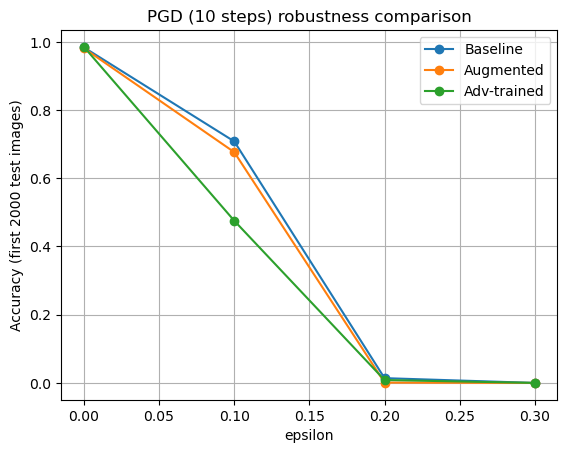

In [24]:
def pgd(model, x, y, eps, steps=10):
    alpha = eps / 4
    x = x.clone().detach().to(device); y = y.to(device)
    x_adv = torch.clamp(x + torch.empty_like(x).uniform_(-eps, eps), 0, 1)   # random start
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad = torch.autograd.grad(loss, x_adv)[0]
        x_adv = x_adv.detach() + alpha * grad.sign()               # small FGSM step
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps)      # stay within eps of the original
        x_adv = torch.clamp(x_adv, 0, 1).detach()                  # stay a valid image
    return x_adv

# first 2000 test images to keep it fast
sub_test = torch.utils.data.Subset(test, range(2000))
sub_test_loader = DataLoader(sub_test, batch_size=250)

def acc_pgd(model, eps):
    model.eval(); correct = 0
    for x, y in sub_test_loader:
        x_adv = pgd(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x_adv).argmax(1).cpu() == y).sum().item()
    return correct / len(sub_test)

pgd_eps = [0, 0.1, 0.2, 0.3]
models = {"Baseline": final, "Augmented": aug_model, "Adv-trained": adv_model}
pgd_results = {name: [acc_pgd(m, e) for e in pgd_eps] for name, m in models.items()}

df_pgd = pd.DataFrame(pgd_results, index=pgd_eps)
df_pgd.index.name = "epsilon"
print(df_pgd.round(4))
df_pgd.to_csv("pgd_results.csv")

df_pgd.plot(marker="o"); plt.ylabel("Accuracy (first 2000 test images)")
plt.title("PGD (10 steps) robustness comparison"); plt.grid(True)
plt.savefig("pgd_comparison.png", dpi=150); plt.show()

In [25]:
import os
print(os.getcwd())
print([f for f in os.listdir() if f.endswith((".pt", ".csv", ".png", ".ipynb"))])

/Users/abdulhaseebmalik
['pgd_results.csv', 'Untitled1.ipynb', 'CNN_pretrained_networks.ipynb', 'cnn_adv.pt', 'Untitled3.ipynb', 'Untitled.ipynb', 'cnn_baseline.pt', 'Advanced Data science.ipynb', 'Untitled4.ipynb', 'heart.csv', 'wearable_health_devices_performance_upto_26june2025.csv', 'Project NIT2251-S8130918.ipynb', 'Hands on exercise session 3.ipynb', 'lime_examples.png', 'Untitled2.ipynb', 'mnist_convnet.ipynb', 'Traffic_Sign_Classification.ipynb', 'Case Study Python Implementation.ipynb', 'fgsm_curve.png', 'boston_housing.csv', 'fgsm_examples.png', 'fgsm_comparison.png', 'CaseStudy1.ipynb', 'cnn_final.pt', 'pgd_comparison.png']


In [26]:
import os, shutil

src = "/Users/abdulhaseebmalik"
dst = os.path.join(src, "mnist-project")
os.makedirs(dst, exist_ok=True)

files = [
    "Untitled4.ipynb",
    "lime_examples.png", "fgsm_curve.png", "fgsm_examples.png",
    "fgsm_comparison.png", "pgd_comparison.png",
    "pgd_results.csv", "cnn_final.pt", "cnn_adv.pt",
]

for f in files:
    p = os.path.join(src, f)
    if os.path.exists(p):
        shutil.copy(p, dst)
        print("copied", f)
    else:
        print("MISSING", f)

with open(os.path.join(dst, "requirements.txt"), "w") as r:
    r.write("torch\ntorchvision\nlime\nscikit-image\nmatplotlib\nscikit-learn\nseaborn\npandas\nnumpy\n")

with open(os.path.join(dst, "README.md"), "w") as r:
    r.write("""# Handwritten Digit Recognition Using CNN and Explainable AI (XAI)

Name: Haseeb Malik
Student ID: s8130918
Note: This project was completed individually.

Contents: CNN on MNIST, LIME explanations, FGSM and PGD adversarial attacks.
Data: MNIST is downloaded automatically by torchvision.
To run: open Untitled4.ipynb and run all cells from top to bottom.
""")

print("Done. Folder:", dst)

copied Untitled4.ipynb
copied lime_examples.png
copied fgsm_curve.png
copied fgsm_examples.png
copied fgsm_comparison.png
copied pgd_comparison.png
copied pgd_results.csv
copied cnn_final.pt
copied cnn_adv.pt
Done. Folder: /Users/abdulhaseebmalik/mnist-project


In [27]:
os.system("open /Users/abdulhaseebmalik/Desktop/mnist-project")

The file /Users/abdulhaseebmalik/Desktop/mnist-project does not exist.


256